# Single-point diffusion model

This model follows the finite-difference method used in `IM_Diffusion_solutions.ipynb`. Advection is disabled by setting the wind speed to zero, so the equation is $c_t=Dc_{xx}$. A single source point is represented by a narrow difference of sigmoid functions.

In [27]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
%matplotlib inline


In [28]:
# Parameters
L = 1.0
D = 2
advection_speed = 0.0  # diffusion only
x0 = 0.35               # source point
source_width = 0.04
sigmoid_scale = 0.006
source_strength = 1.0
T = 0.01

# Grid and stable explicit-Euler time step
M = 250
x = np.linspace(0.0, L, M + 1)
dx = x[1] - x[0]
dt = 0.45 * dx**2 / D
N = int(np.ceil(T / dt))
dt = T / N
t = np.linspace(0.0, T, N + 1)
C = D * dt / dx**2

if D <= 0.0:
    raise ValueError('D must be positive.')
if advection_speed != 0.0:
    raise ValueError('Set advection_speed to zero for diffusion only.')
if C > 0.5:
    raise ValueError(f'Unstable time step: D*dt/dx^2 = {C:.3f}')
print(f'dx={dx:.3e}, dt={dt:.3e}, N={N}, D*dt/dx^2={C:.3f}')


dx=4.000e-03, dt=3.600e-06, N=2778, D*dt/dx^2=0.450


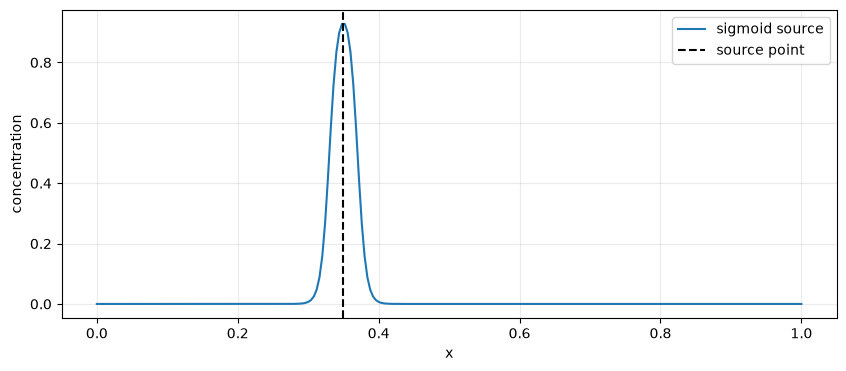

In [ ]:
def sigmoid(x):
    return 1.0 / (1.0 + np.exp(-x))

def single_point_profile(x, x0, width, scale, amplitude):
    left = sigmoid((x - (x0 - width / 2.0)) / scale)
    right = sigmoid((x - (x0 + width / 2.0)) / scale)
    return amplitude * (left - right)

initial = single_point_profile(
    x, x0, source_width, sigmoid_scale, source_strength
)
plt.figure(figsize=(10, 4))
plt.plot(x, initial, label='sigmoid source')
plt.axvline(x0, color='black', linestyle='--', label='source point')
plt.xlabel('x')
plt.ylabel('concentration')
plt.legend()
plt.grid(alpha=0.25)
plt.show()


For interior points, forward Euler gives $C_m^{n+1}=C_m^n+C(C_{m-1}^n-2C_m^n+C_{m+1}^n)$, where $C=D\Delta t/\Delta x^2$. Mirrored ghost points impose zero-flux boundaries.

In [30]:
solution = np.zeros((N + 1, M + 1))
solution[0] = initial

for n in range(N):
    current = solution[n]
    updated = current.copy()
    updated[1:-1] = current[1:-1] + C * (
        current[:-2] - 2.0 * current[1:-1] + current[2:]
    )
    updated[0] = current[0] + 2.0 * C * (current[1] - current[0])
    updated[-1] = current[-1] + 2.0 * C * (current[-2] - current[-1])
    solution[n + 1] = updated

if solution.min() < -1e-12:
    raise RuntimeError('Negative concentration detected; reduce the time step.')


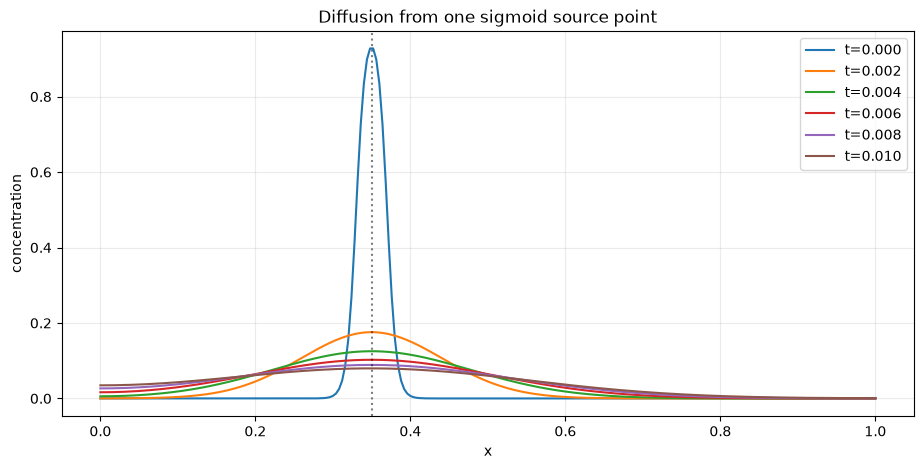

Relative mass change: 3.469e-16


In [31]:
indices = np.linspace(0, N, 6, dtype=int)
plt.figure(figsize=(11, 5))
for i in indices:
    plt.plot(x, solution[i], label=f't={t[i]:.3f}')
plt.axvline(x0, color='black', linestyle=':', alpha=0.5)
plt.xlabel('x')
plt.ylabel('concentration')
plt.title('Diffusion from one sigmoid source point')
plt.legend()
plt.grid(alpha=0.25)
plt.show()
integrate = np.trapezoid if hasattr(np, 'trapezoid') else np.trapz
mass = integrate(solution, x, axis=1)
print(f'Relative mass change: {(mass[-1] - mass[0]) / mass[0]:.3e}')


## Live animation

The animation displays the concentration profile as it diffuses from the single source point. The time shown is the numerical time used by the finite-difference solver.

In [32]:
fig, ax = plt.subplots(figsize=(11, 5))
line, = ax.plot(x, solution[0], color='tab:blue', linewidth=2)
source_line = ax.axvline(x0, color='black', linestyle=':', alpha=0.6)
time_label = ax.text(0.02, 0.94, '', transform=ax.transAxes)

ax.set_xlim(0.0, L)
ax.set_ylim(0.0, 1.05 * solution.max())
ax.set_xlabel('x')
ax.set_ylabel('concentration')
ax.set_title('Diffusion from one sigmoid source point')
ax.grid(alpha=0.25)

def update(frame):
    line.set_ydata(solution[frame])
    time_label.set_text(f't = {t[frame]:.3f}')
    return line, time_label

animation = FuncAnimation(
    fig, update, frames=len(t), interval=40, blit=True, repeat=True
)
plt.close(fig)
HTML(animation.to_jshtml())


Animation size has reached 20971970 bytes, exceeding the limit of 20971520.0. If you're sure you want a larger animation embedded, set the animation.embed_limit rc parameter to a larger value (in MB). This and further frames will be dropped.
